In [234]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

1 этап) Загрузка и первичный просмотр данных


In [235]:
user = pd.read_excel("dannye-dlia-keisa-po-pa-cebbefc3-5b29-4f88-b6d4-3336c88d743f.xlsx", sheet_name="Пользователи")
payment = pd.read_excel("dannye-dlia-keisa-po-pa-cebbefc3-5b29-4f88-b6d4-3336c88d743f.xlsx", sheet_name="Платежи")


In [236]:
user.head(20)

,user_id,group,age,city,device_type
0,1001,A,31,Москва,ios
1,1002,A,31,Москва,ios
2,1003,A,25,Москва,android
3,1004,A,20,Москва,ios
4,1005,A,34,Москва,ios
5,1006,A,42,Регион,android
6,1007,A,34,Регион,ios
7,1008,A,43,Регион,ios
8,1009,A,30,Москва,android
9,1010,A,26,Москва,android


In [237]:
user["city"].value_counts()

city
Москва    595
Регион    514
СПб       394
Name: count, dtype: int64

In [238]:
user.device_type.value_counts()

device_type
android    777
ios        727
Name: count, dtype: int64

In [239]:
payment.head(20)

,payment_id,user_id,group,step1_opened,step2_entered,step3_confirmed,step4_success
0,5001,1001.0,A,2024-04-16 06:06:00,2024-04-16 06:10:00,NaT,NaT
1,5002,1002.0,A,2024-04-12 07:38:00,2024-04-12 07:41:00,NaT,NaT
2,5003,1003.0,A,2024-04-26 20:03:00,2024-04-26 20:07:00,NaT,NaT
3,5004,1004.0,A,2024-04-09 16:02:00,NaT,NaT,NaT
4,5005,1004.0,A,2024-04-04 03:46:00,2024-04-04 03:54:00,2024-04-04 03:57:00,2024-04-04 04:02:00
5,5006,1004.0,A,2024-04-24 17:26:00,2024-04-24 17:27:00,2024-04-24 17:30:00,2024-04-24 17:36:00
6,5007,1005.0,A,2024-04-11 21:10:00,2024-04-11 21:11:00,NaT,NaT
7,5008,1006.0,A,2024-04-12 13:48:00,2024-04-12 13:52:00,2024-04-12 13:55:00,2024-04-12 14:00:00
8,5009,1007.0,A,2024-04-09 11:28:00,2024-04-09 11:30:00,2024-04-09 11:35:00,2024-04-09 11:42:00
9,5010,1007.0,A,2024-04-08 06:54:00,NaT,NaT,NaT


In [240]:
user.info()

<class 'pandas.DataFrame'>
RangeIndex: 1504 entries, 0 to 1503
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   user_id      1504 non-null   int64
 1   group        1503 non-null   str  
 2   age          1504 non-null   int64
 3   city         1503 non-null   str  
 4   device_type  1504 non-null   str  
dtypes: int64(2), str(3)
memory usage: 58.9 KB


Здесь можно увидеть, что есть несколько пользователей (1-2), у которых нет группы и города.


Перейдем к платежам.


In [241]:
payment.info()

<class 'pandas.DataFrame'>
RangeIndex: 2661 entries, 0 to 2660
Data columns (total 7 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   payment_id       2661 non-null   int64         
 1   user_id          2660 non-null   float64       
 2   group            2661 non-null   str           
 3   step1_opened     2661 non-null   datetime64[us]
 4   step2_entered    2256 non-null   datetime64[us]
 5   step3_confirmed  1719 non-null   datetime64[us]
 6   step4_success    1522 non-null   datetime64[us]
dtypes: datetime64[us](4), float64(1), int64(1), str(1)
memory usage: 145.7 KB


In [242]:
payment["group"].value_counts()

group
B    1352
A    1309
Name: count, dtype: int64

По платежам можно заметить, что один платеж не привязан ни к одному ID, и воронка постепенно сужается. Также записей в платежах больше, чем записей в пользователях. Это может означать, что есть пользователи, которые несколько раз пытались оплатить ЖКХ.


In [243]:
user["age"].describe()

count    1504.000000
mean       32.745346
std         8.410915
min        -5.000000
25%        27.000000
50%        33.000000
75%        38.000000
max       150.000000
Name: age, dtype: float64

Метод `describe()` по платежам не даст полезной информации, поскольку там содержатся даты, поэтому применять его не будем.


Теперь необходимо отфильтровать датасет от аномальных значений: записей без принадлежности к группе А или В, платежей без ID и т.д.


In [244]:
new_user = user[(user["age"] >= 18) & (user["age"] <= 100) & (~user["group"].isna()) & (~user["city"].isna())]
new_user["age"].describe()

count    1500.000000
mean       32.699333
std         7.795048
min        20.000000
25%        27.000000
50%        33.000000
75%        38.000000
max        60.000000
Name: age, dtype: float64

In [245]:
new_payment = payment[(~payment["user_id"].isna()) & (~payment["group"].isna())]
new_payment.info()

<class 'pandas.DataFrame'>
RangeIndex: 2660 entries, 0 to 2659
Data columns (total 7 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   payment_id       2660 non-null   int64         
 1   user_id          2660 non-null   float64       
 2   group            2660 non-null   str           
 3   step1_opened     2660 non-null   datetime64[us]
 4   step2_entered    2256 non-null   datetime64[us]
 5   step3_confirmed  1719 non-null   datetime64[us]
 6   step4_success    1522 non-null   datetime64[us]
dtypes: datetime64[us](4), float64(1), int64(1), str(1)
memory usage: 145.6 KB


Объединяем две таблицы в один датасет для удобства.


In [246]:
df = new_payment.merge(new_user, on = "user_id", how = "inner")
df.head(5)

,payment_id,user_id,group_x,step1_opened,step2_entered,step3_confirmed,step4_success,group_y,age,city,device_type
0,5001,1001.0,A,2024-04-16 06:06:00,2024-04-16 06:10:00,NaT,NaT,A,31,Москва,ios
1,5002,1002.0,A,2024-04-12 07:38:00,2024-04-12 07:41:00,NaT,NaT,A,31,Москва,ios
2,5003,1003.0,A,2024-04-26 20:03:00,2024-04-26 20:07:00,NaT,NaT,A,25,Москва,android
3,5004,1004.0,A,2024-04-09 16:02:00,NaT,NaT,NaT,A,20,Москва,ios
4,5005,1004.0,A,2024-04-04 03:46:00,2024-04-04 03:54:00,2024-04-04 03:57:00,2024-04-04 04:02:00,A,20,Москва,ios


Уберем дублирующиеся колонки и переименуем их для удобства.


In [247]:
df = df.drop(columns = ["group_y"])

df = df.rename(columns = {"group_x": "group"})

Также проверим сопоставимость групп А и В по ключевым признакам (город, тип устройства, возраст) с помощью критерия хи-квадрат.


In [248]:
check1 = pd.crosstab(new_user["group"], user["city"])

In [249]:
check2 = pd.crosstab(new_user["group"], user["device_type"])

Напишем класс для расчета хи-квадрата. Выбираем его, поскольку город и тип устройства — категориальные признаки.


In [250]:
from scipy.stats import chi2
class Xi2:
    def __init__(self, data):
        self.data = data

    def solve(self):
        self.row_sums = self.data.sum(axis = 1) # сумма по строкам
        self.col_sums = self.data.sum(axis = 0)# по столбцам
        self.total = self.data.sum().sum() # общее количество людей в целом
        self.e = np.outer(self.row_sums, self.col_sums)/self.total # матрица ожидаемых значений

        self.xi2 = ((self.data-self.e)**2/self.e).sum().sum() # xi2

    def pvalue(self):
        dof = (self.data.shape[0]-1)*(self.data.shape[1]-1) # степень свободы для таблицы
        return 1 - chi2.cdf(self.xi2, dof)
        


In [251]:

# Запускаем класс
test_check1 = Xi2(check1)
test_check2 = Xi2(check2)
test_check1.solve()
test_check2.solve()
print(f"Xi2 между группой и городом = {round(test_check1.xi2, 3)}, между группой и  типом устройства = {round(test_check2.xi2, 3)}")
print(f"p-value (город) = {test_check1.pvalue():.3f}")
print(f"p-value (устройство) = {test_check2.pvalue():.3f}")


Xi2 между группой и городом = 1.64, между группой и  типом устройства = 3.655
p-value (город) = 0.440
p-value (устройство) = 0.056


Чуть ниже проверим сопоставимость также по признаку «возраст».


Возраст — непрерывная величина, поэтому для него будем использовать T-критерий Стьюдента.


Как можно заметить по результатам, разбиение на группы действительно случайное, без перекосов по какому-либо из признаков (p-value > 0.05).


Создадим колонку-флаг, чтобы понять, где получилось оплатить, а где нет. Будем использовать ее далее для группировки по каждому пользователю, где `groupby` даст либо 1, либо 0.


In [252]:
df["successed"] = ~df["step4_success"].isna()

In [253]:
grouped = df[["user_id", "group", "successed"]].groupby(by = "user_id").agg({"successed": "max", "group": "first"})


grouped = df[["user_id", "age", "group", "device_type", "successed", "city"]].groupby(by="user_id").agg({
    "successed": "max",
    "group": "first",
    "device_type": "first",
    "city":"first",
    "age":"first"
})
new_df = grouped.reset_index()

Как и упоминалось ранее, проверим сопоставимость групп по возрасту. Использовать будем T-критерий Стьюдента, поскольку в отличие от города или типа устройства, которые являются категориальными переменными, возраст — непрерывная величина.


In [254]:
from scipy.stats import ttest_ind

# Берем колонку возраста для каждой группы
age_A = new_df[new_df['group'] == 'A']['age']
age_B = new_df[new_df['group'] == 'B']['age']

# Запускаем t-test
stat, p_value_age = ttest_ind(age_A, age_B)
print(f"p-value (возраст) = {p_value_age:.3f}")


p-value (возраст) = 0.824


Здесь `p-value > 0.05`, что означает, что средний возраст пользователей в группах статистически не различается.


Здесь (относится к блоку перед проверкой сопоставимости по возрасту) можно увидеть, что у некоторых клиентов количество оплат превысило 1 раз за месяц. Если пользователь совершал несколько попыток оплаты, успехом мы будем считать наличие хотя бы одной успешной оплаты за период теста.


In [255]:
new_df = grouped.reset_index()
A_conv = round(new_df[new_df["group"] == "A"]["successed"].mean(), 3)
B_conv = round(new_df[new_df["group"] != "A"]["successed"].mean(), 3)
print(A_conv, B_conv, sep = "\n")

0.657
0.804


Как можно заметить по результатам, конверсия группы В выше, чем у группы А. Разница довольно высокая — почти 15 процентных пунктов. Какова вероятность того, что эта разница — просто случайность?


Для ответа на этот вопрос сформулируем две гипотезы:

**H0 (Нулевая гипотеза):** Разница в 15% — это случайное совпадение, упрощение заполнения реквизитов ни на что не влияет.

**H1 (Альтернативная гипотеза):** Разница в 15% не случайна, новая форма действительно работает лучше.


Для сравнения полученных конверсий мы будем использовать Z-критерий (Z-test for proportions), поскольку для этого есть три причины:

1. Бинарность нашей метрики (оплата прошла или нет).
2. Группы А и В независимы друг от друга.
3. Размер выборки в обеих группах достаточен (~750 записей в каждой).


Подготовим базовые цифры для нахождения Z-score.


In [256]:
# количество успехов в 2 группах
A_suc = new_df[new_df["group"] == "A"]["successed"].sum()
B_suc = new_df[new_df["group"] != "A"]["successed"].sum()


#общее кол-во пользователей
A_count = len(new_df[new_df["group"] == "A"])
B_count = len(new_df[new_df["group"] != "A"])



#расчет общей доли успехов без дифференциации по группам
suc = (A_suc + B_suc)/(A_count+B_count)



# расчитаем еще стандартное отклонение между 2 группами (через дисперсию распределения Бернулли)
p = np.sqrt(suc * (1- suc) * (1/A_count + 1/B_count))


# рассчитываем z
z = (B_suc/B_count - A_suc/A_count)/p
print(z)


6.402393383329898


Рассчитаем еще p-value.


In [257]:
from scipy.stats import norm

p_value = 2 * (1 - norm.cdf(abs(z)))
diff = B_conv - A_conv
ci_low, ci_high = diff - 1.96*p, diff + 1.96*p
print(f"p-value = {p_value:.5f}")
print(f"Разница конверсий: {diff:.3f}, 95% доверительный интервал: [{ci_low:.3f}, {ci_high:.3f}]")

p-value = 0.00000
Разница конверсий: 0.147, 95% доверительный интервал: [0.102, 0.192]


Полученное значение  = 6.40$ соответствует  < 0.001$, что позволяет уверенно отклонить нулевую гипотезу (H0). 95%-й доверительный интервал разницы конверсий не включает ноль.


Перейдем к визуализации результатов.


/var/folders/8m/fmz_cj0x64n4dh170vg54ggc0000gn/T/ipykernel_28237/1391889675.py:68: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=new_df, x='group', y='age', palette='deep', ax = ax5)


Text(0, 0.5, 'Группы')

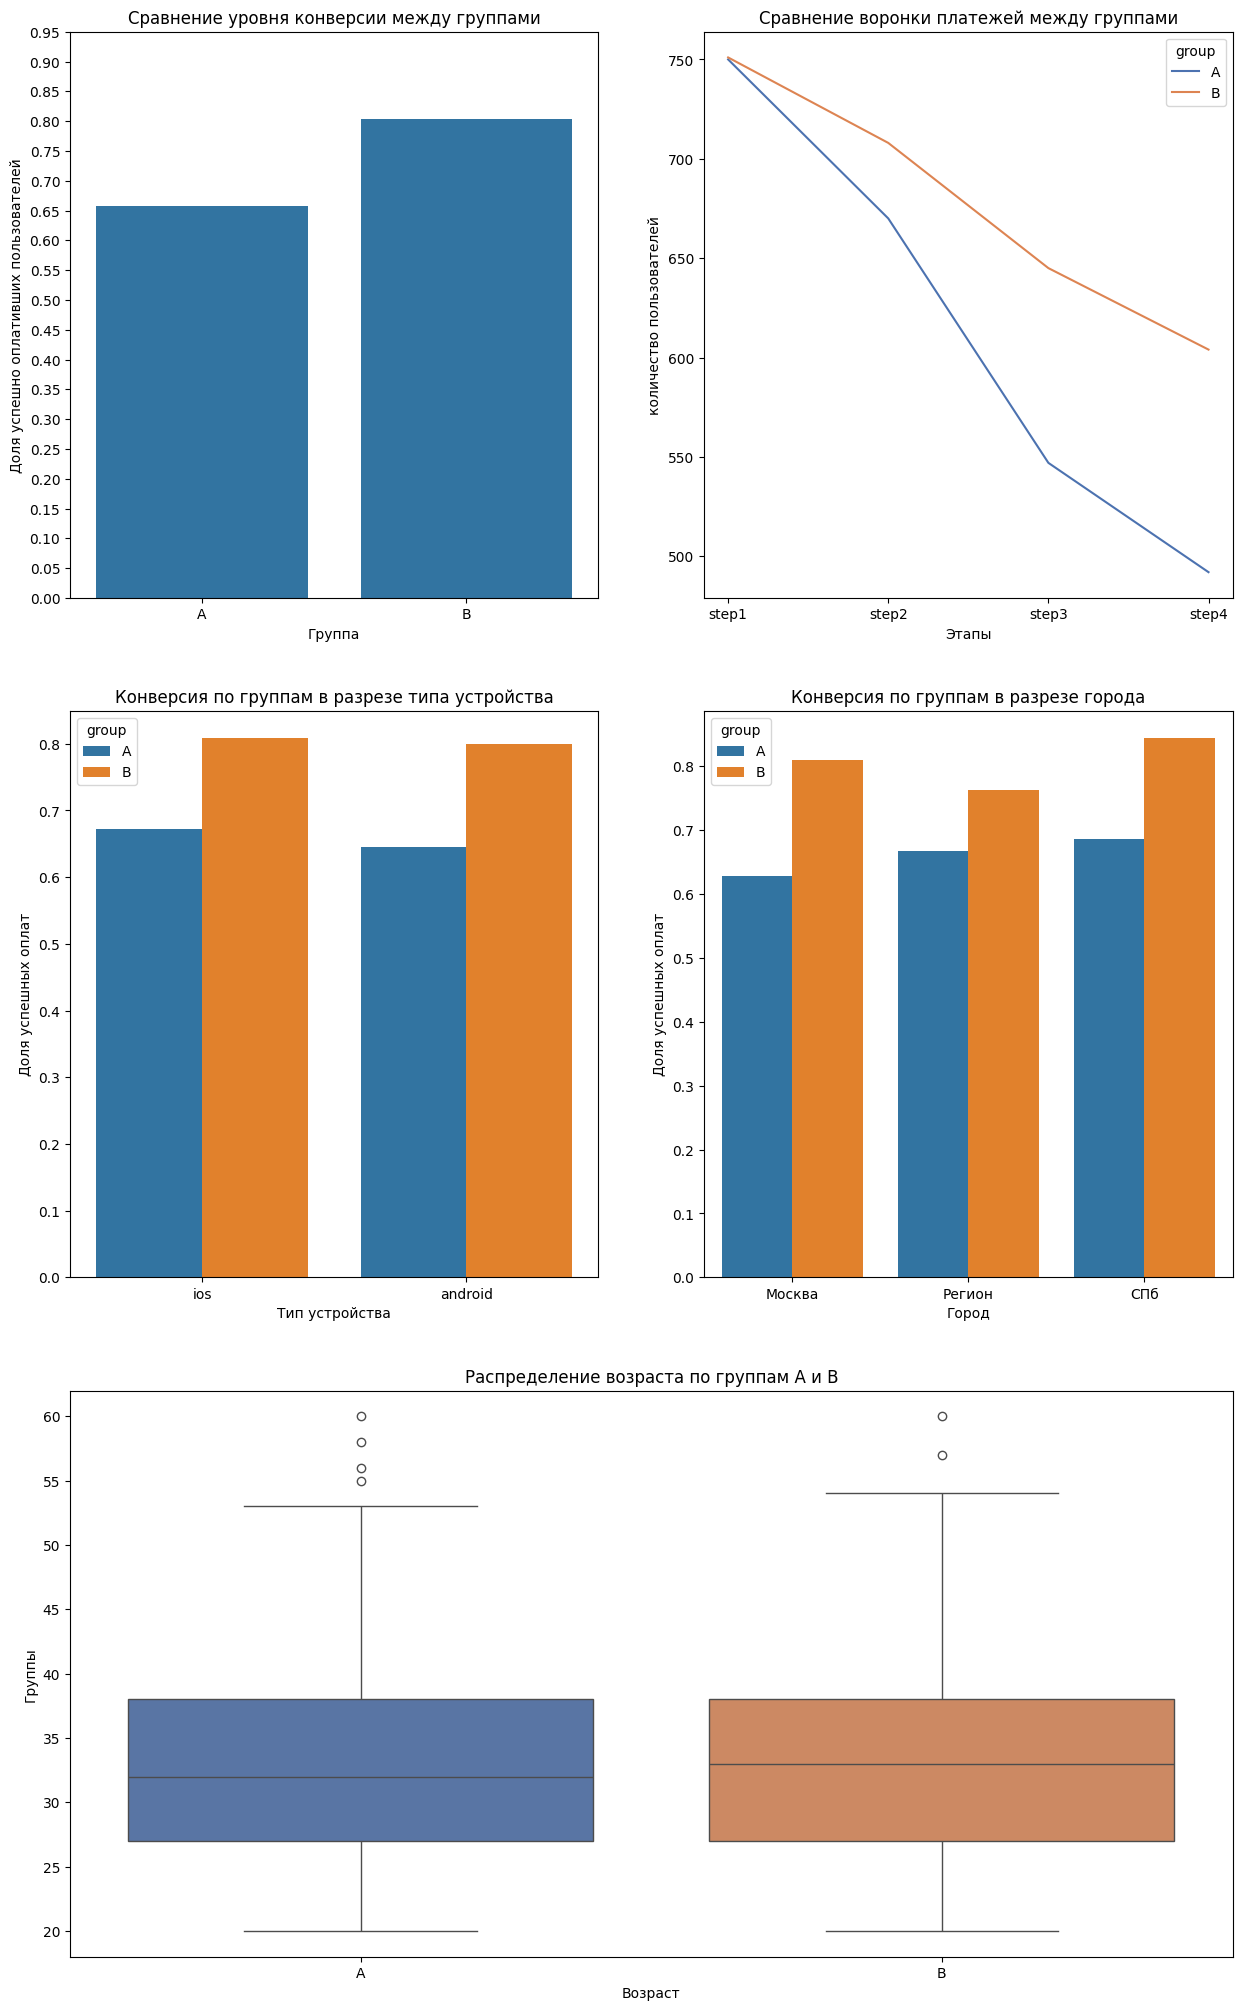

In [261]:
fig = plt.figure(figsize = (15, 25))


gs = fig.add_gridspec(nrows = 3, ncols= 2)
ax1 = fig.add_subplot(gs[0, 0])
ax2 = fig.add_subplot(gs[0, 1])
ax3 = fig.add_subplot(gs[1, 0])
ax4 = fig.add_subplot(gs[1, 1])
ax5 = fig.add_subplot(gs[2, :])



sns.barplot(data = new_df, x = "group", y = "successed", ax = ax1, errorbar=None)
ax1.set_yticks(np.arange(0, 1, 0.05))
ax1.set_title("Сравнение уровня конверсии между группами")
ax1.set_ylabel("Доля успешно оплативших пользователей")
ax1.set_xlabel("Группа")

#подготовим данные для визуализации через lineplot(буду визуализировать 2 воронки у 2 групп)

class Step_count:
    def __init__(self, name, data):
        self.name = name
        self.data = data


    def count(self):
        self.step1 = self.data[(self.data["step1_opened"].notna()) & (self.data["group"] == self.name)]["user_id"].nunique()
        self.step2 = self.data[(self.data["step2_entered"].notna()) & (self.data["group"] == self.name)]["user_id"].nunique()
        self.step3 = self.data[(self.data["step3_confirmed"].notna()) & (self.data["group"] == self.name)]["user_id"].nunique()
        self.step4 = self.data[(self.data["step4_success"].notna()) & (self.data["group"] == self.name)]["user_id"].nunique()
        data_for_dataframe = {"step": ["step1", "step2", "step3", "step4"],"count": [self.step1, self.step2, self.step3, self.step4], "group": None}
        self.result = pd.DataFrame(data_for_dataframe)
        self.result["group"] = self.name

#посчитаем для А и В

a = Step_count("A", df)
b = Step_count("B", df)


a.count()
b.count()

f =  pd.concat((a.result, b.result))


sns.lineplot(data = f, ax = ax2, x = "step", y = "count", hue = "group", palette = "deep")
ax2.set_title("Сравнение воронки платежей между группами")
ax2.set_xlabel("Этапы")
ax2.set_ylabel("количество пользователей")


sns.barplot(data=new_df, x="device_type", y="successed", hue="group", errorbar=None, ax=ax3)
ax3.set_title("Конверсия по группам в разрезе типа устройства")
ax3.set_ylabel("Доля успешных оплат")
ax3.set_xlabel("Тип устройства")




sns.barplot(data=new_df, x="city", y="successed", hue="group", errorbar=None, ax=ax4)
ax4.set_title("Конверсия по группам в разрезе города")
ax4.set_ylabel("Доля успешных оплат")
ax4.set_xlabel("Город")


sns.boxplot(data=new_df, x='group', y='age', palette='deep', ax = ax5)
plt.title('Распределение возраста по группам А и В')

ax5.set_xlabel("Возраст")
ax5.set_ylabel("Группы")






Графики показывают, что новая форма оплаты в тестовой группе В дает равномерный прирост конверсии независимо от сегмента пользователя (будь то город или тип устройства).


In [259]:
extra_conversions = diff * B_count
print(f"Доп. успешно-оплативших пользователей на {B_count} пользователей группы B: {extra_conversions:.0f}")

Доп. успешно-оплативших пользователей на 750 пользователей группы B: 110


Разница в 14.7 п.п. практически значима: в тестовой группе В на каждые ~750 пользователей (весь тестовый сегмент В) приходится примерно на 110 больше успешно оплативших ЖКХ по сравнению со сценарием группы А.
